# Week 3 · Records and data

One offer is easy. A real day has many. This week you keep one record per offer, add them up, and find any offer by its ID.

| | |
|---|---|
| **This week's question** | How does a system remember many things and tell them apart? |
| **Python you will learn** | lists, dictionaries, a list of dictionaries, `for` loops, the accumulator pattern, finding by ID |
| **Principle 3** | **One record per real thing.** Each thing gets one record and one unique ID. Do not store the same fact twice. |
| **Part you build** | `total_portions` and `find_offer` (⭐⭐ `portions_by_category`) |

*Campus FoodBridge is fictional. All organisations, people and numbers are invented.*

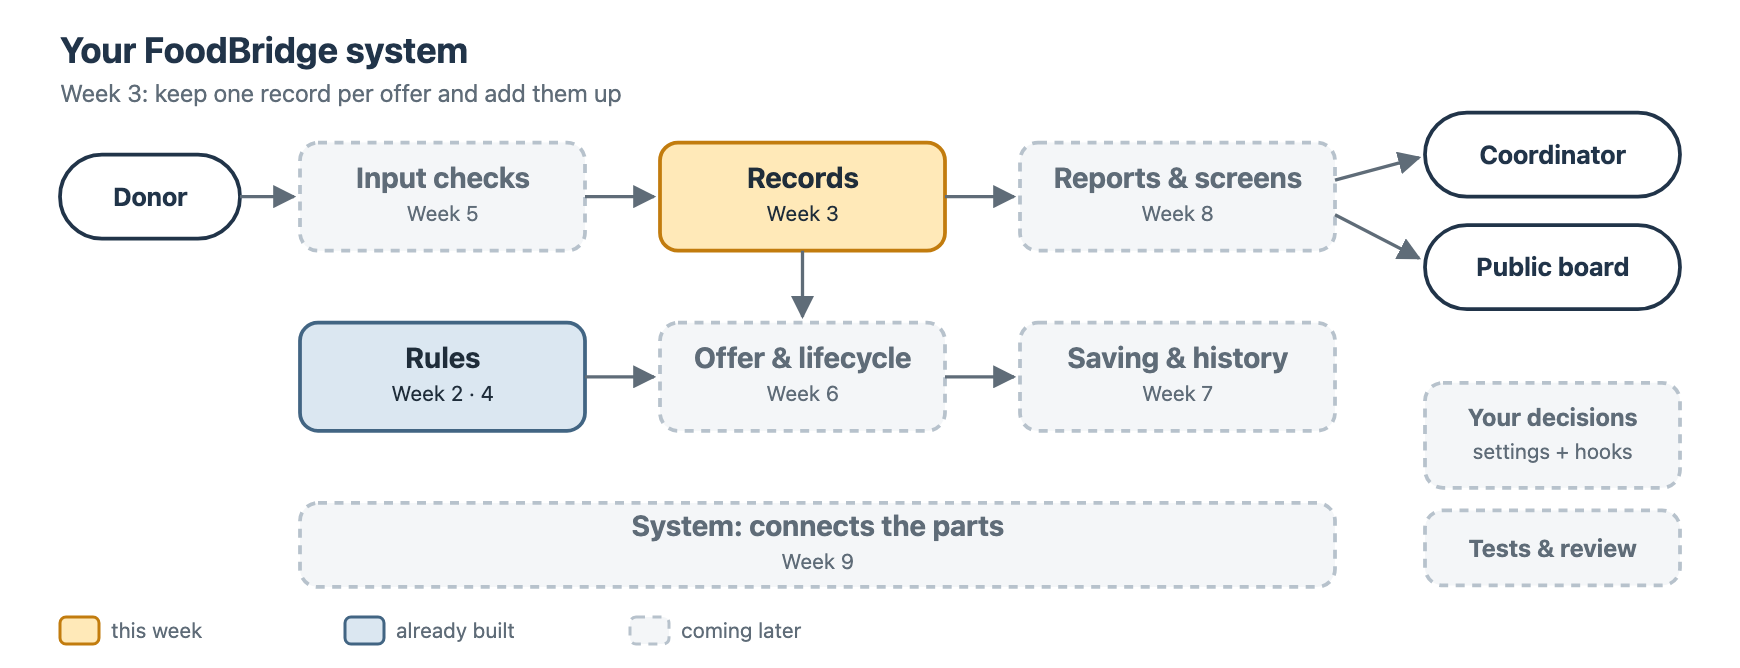

### The story so far

Your Week 2 rules work. This morning, the phone tests them. At 7:30 Sunrise Bakery calls with 30 portions of bread rolls, then the Campus Canteen, Green Market Stall and Lotus Cafe. Four offers, and the paper notebook is already a mess, with one number written twice.

Rules are not enough. A system must also **remember**: every offer kept apart, nothing lost, nothing counted twice.

## Before you start

1. Click **Copy to Drive** (or **File → Save a copy in Drive**), then work in your copy.
2. Run the setup cell. Run it again after a runtime restart.
3. ⭐ = core for everyone, ⭐⭐ = optional stretch.

In [ ]:
# @title ▶ Run this cell first (setup) — it prepares the FoodBridge system
# It unpacks the course system that is stored inside this notebook.
# No internet, no installation. Run it again after Colab restarts.
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.8"
_KIT_SHA = "41dafebb7ed52e8114e8bc10c2d9edb023f9aed5e823f1af14589289780e44f5"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("This notebook's course files are damaged. Download a fresh copy.")
    marker = os.path.join("foodbridge_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("foodbridge_kit/my_settings.py", "foodbridge_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("foodbridge_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "foodbridge" or m.startswith("foodbridge.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import foodbridge as bridge
print("✅ FoodBridge system ready (version " + bridge.KIT_VERSION + "). You can continue.")


### Warm-up · The boundary from Week 2

Last week's rule: **20 portions or more need a team.** 🤔 **Predict** `needs_team(19)`, `needs_team(20)` and `needs_team(21)`, then complete the function.

In [ ]:
TEAM_PICKUP_MIN_PORTIONS = 20

def needs_team(portions):
    # TODO: return True when portions is at least TEAM_PICKUP_MIN_PORTIONS, otherwise False
    return None

bridge.check("needs_team", needs_team, examples=[(19, False), (20, True), (21, True)])

## Class warm-up · Research 2 exchange (10 min)

In groups of three, share the rule you researched.

1. Read your rule aloud, exactly. Can your group find a case it does not cover?
2. Share your **boundary** case. Does everyone agree what happens exactly at the limit?
3. Share your **odd** case (missing, negative or unusual input). What should the system do, and who decides?

📝 **One edge case from a classmate that I want to remember:**

## Session 1 · Learn and try: many records (75 min)

### The idea: records, IDs and the data model

Think of a class list. Each student is **one row**, and every row has the same columns: student ID, name, class. Two students can share a name, but never a student ID. The office looks you up by ID.

Our system works the same way. Each offer is one **record**: the facts about one real offer. Every record has the same **fields** and one unique **ID**, such as `"F001"`. The list of fields is the **data model**; choosing it is a design decision.

| Field | Example | Why we keep it |
|---|---|---|
| `id` | `"F001"` | tell offers apart, even with the same food |
| `donor`, `contact` | `"Sunrise Bakery"`, `"sunrise@example.org"` | thank and call back (contact is private) |
| `food`, `category` | `"Bread rolls"`, `"bread"` | what it is; the category decides if we accept it |
| `portions`, `hours_left` | `30`, `5` | how much, and how soon |
| `status`, `partner` | `"approved"`, `"Hope Children's Centre"` | where it is, who receives it |

- **Why an ID, not the food name?** Two bakeries can both offer "Bread rolls", and a donor can correct a food name. An ID is never shared and never changes.
- **Why no "total portions today" field?** A total is **calculated** from the records when needed. Stored too, it would be the same fact twice, and one day the copies would disagree.

### 1 · A list keeps many values in order

- Square brackets `[ ]` make a list. `volunteers[0]` is the **first** item; the position is the **index**.
- `len(...)` counts the items. `.append(...)` adds one at the end. `in` gives `True` or `False`.

▶ [Animation: A list: index, `append`, `len`](https://loem-ms.github.io/programming-for-information-systems-site/assets/anim/anim_list.html) (course website)

🤔 **Predict** each line. What will `volunteers[3]` be after the `append`?

In [ ]:
volunteers = ["Dara", "Sophea", "Vanna"]
print(volunteers[0])          # positions start at 0
print(len(volunteers))        # how many items
volunteers.append("Kosal")    # add one at the end
print(volunteers[3])
print("Sophea" in volunteers) # is it in the list?
# print(volunteers[4])        # remove the # to see the error, then put it back

**Prediction:** …  **Result:** …

`volunteers[4]` stops with `IndexError: list index out of range`: there is no fifth item. Read the last line of an error first.

### 2 · A dictionary gives each value a name

A **dictionary** stores pairs: a **key** (the name) and a **value**. You look up a value by its key, not by a position.

🤔 **Predict** the last two lines.

In [ ]:
item = {"name": "Notebook", "price_riel": 4000}
print(item["price_riel"])
item["price_riel"] = 3500        # change a value
item["colour"] = "blue"          # add a new key
print(item)
print(item.get("size"))
print(item.get("size", "one size"))

**Prediction:** …  **Result:** …

- Curly brackets `{ }` make a dictionary, with pairs written `key: value`. Keys are exact: `"Price_riel"` is a different key.
- `item["size"]` stops with a `KeyError`. `.get("size")` gives `None` instead, and `.get("size", "one size")` gives a **default** you choose.

### ✍️ Try it 1 · `stock_of`

A shop keeps its stock in a dictionary: item → how many are left. Write `stock_of(stock, item)`: the number left, or `0` when the shop does not sell the item. Use `.get` with a default. Each example is *(inputs, expected output)*; two inputs go in brackets.

In [ ]:
def stock_of(stock, item):
    # TODO: return the number for this item, or 0 when it is not a key
    return None

shop_stock = {"notebook": 25, "pen": 40, "ruler": 0}
bridge.check("stock_of", stock_of, examples=[
    ((shop_stock, "pen"), 40),
    ((shop_stock, "ruler"), 0),
    ((shop_stock, "eraser"), 0),
])

A default is a decision: here "not sold" and "sold out" both mean 0 left.

### 3 · A record is a dictionary, and a day is a list of records

One offer is one dictionary. Many offers are a **list of dictionaries**: the shape of almost every information system, from a class list to a bank statement. `offers[1]["food"]` has two steps: first the **position** in the list, then the **key** in the record.

▶ [Animation: A dictionary: key → value, records, find by ID](https://loem-ms.github.io/programming-for-information-systems-site/assets/anim/anim_dict.html) (course website)

### 4 · `for`: do the same thing for every record

A **loop** runs the indented lines once for each item. The name after `for` points to the current item. Use a **plural** name for the list (`offers`) and a **singular** name for one item (`offer`).

🤔 **Predict:** what is `offers[1]["food"]`? How many lines does the loop print, and how many times does `Done` appear?

In [ ]:
offers = [
    {"id": "F001", "food": "Bread rolls", "portions": 30, "hours_left": 5},
    {"id": "F002", "food": "Fried rice boxes", "portions": 18, "hours_left": 2},
]
print(offers[1]["food"])
for offer in offers:
    print(offer["id"], "·", offer["food"], "·", offer["portions"], "portions")
print("Done")

**Prediction:** …  **Result:** …

### 5 · The accumulator: start, add, use

The coordinator needs **one number** for the whole day, so we keep a running total while the loop runs. This pattern is the **accumulator**.

▶ [Animation: A `for` loop and an accumulator](https://loem-ms.github.io/programming-for-information-systems-site/assets/anim/anim_for_loop.html) (course website)

In [ ]:
prices_riel = [4000, 1500, 2000]
total_riel = 0                    # 1. start before the loop
for price_riel in prices_riel:
    total_riel += price_riel      # 2. add each item
print(total_riel)                 # 3. use the result after the loop

`total_riel += price_riel` means `total_riel = total_riel + price_riel`. The same three steps do more than add:

| Job | Start | Inside the loop |
|---|---|---|
| **add** | `total = 0` | `total += value` |
| **count** | `count = 0` | `count += 1` |
| **filter** | as above | the same line, under an `if` |
| **collect** | `found = []` | `found.append(value)` |

🤔 **Predict:** what prints if `total_riel = 0` moves **inside** the loop (just above the `+=` line)? Try it, then move it back.

**Prediction:** …  **Result:** …  **Why:** …

### ✍️ Try it 2 · `count_passing`

Write `count_passing(marks)`: how many marks are at least `PASS_MARK`. Count and filter: start at 0, add 1 under an `if`.

In [ ]:
PASS_MARK = 50

def count_passing(marks):
    # TODO: start at 0; add 1 for each mark of at least PASS_MARK; return the count
    return None

bridge.check("count_passing", count_passing, examples=[([72, 45, 50, 88], 3), ([10, 20], 0), ([], 0)])

### ✍️ Try it 3 · `total_bill`

A café order is a list of records with `"name"`, `"price_riel"` and `"quantity"`. Write `total_bill(items)`: price × quantity for each line, all added up.

In [ ]:
def total_bill(items):
    # TODO: add up price_riel * quantity for each record
    return None

order = [{"name": "Iced coffee", "price_riel": 6000, "quantity": 2},
         {"name": "Num pang", "price_riel": 4000, "quantity": 1}]
bridge.check("total_bill", total_bill, examples=[(order, 16000), ([], 0)])

The order does not store its bill. Change a quantity, and the bill is simply calculated again: Principle 3.

### 6 · Find one record by its ID

Adding up looks at every record. Finding looks for **one**. When the ID matches, **return** the record: `return` stops the loop at once. Only **after** the loop has checked every record do you know it is not there; then return `None`.

In [ ]:
shop_items = [
    {"code": "N01", "name": "Notebook", "price_riel": 4000},
    {"code": "P02", "name": "Pen", "price_riel": 1500},
]

def find_item(items, wanted_code):
    for item in items:
        if item["code"] == wanted_code:
            return item          # found: stop and send it back
    return None                  # checked every item: not found

print(find_item(shop_items, "P02"))
print(find_item(shop_items, "X99"))

`return None` lines up with `for`, not with `if`: it runs only when the loop has finished without finding anything.

### ✍️ Try it 4 · `find_student`

Both students in this class list are called Dara. Write `find_student(students, student_id)`: the record whose `"id"` equals `student_id`, or `None`.

In [ ]:
def find_student(students, student_id):
    # TODO: loop; return the student whose "id" matches; after the loop, return None
    return "?"

class_list = [{"id": "S01", "name": "Dara", "class": "MIS-1"},
              {"id": "S02", "name": "Dara", "class": "MIS-2"}]
bridge.check("find_student", find_student, examples=[
    ((class_list, "S02"), class_list[1]),
    ((class_list, "S09"), None),
    (([], "S01"), None),
])

A search by **name** would always stop at S01; the Dara in MIS-2 could never be found. A search by **ID** finds exactly one student.

### ✍️ Try it 5 · Back to FoodBridge: `urgent_ids`

The coordinator wants the **IDs** of the urgent offers (3 hours left or less), so a volunteer can phone about each one. Collect them: start with `[]` and `.append` each urgent record's `"id"`. IDs, not food names: two offers can share a food.

In [ ]:
URGENT_HOURS = 3

def urgent_ids(records):
    # TODO: start with []; append the "id" of each urgent record; return the list
    return None

evening = [{"id": "F101", "hours_left": 2}, {"id": "F102", "hours_left": 10}, {"id": "F103", "hours_left": 3}]
bridge.check("urgent_ids", urgent_ids, examples=[
    (evening, ["F101", "F103"]),
    (bridge.sample_records(), ["F002"]),
    ([], []),
])

F103 has exactly 3 hours left. Did you remember the Week 2 boundary? `<=` includes it.

## Session 2 · Practise and judge (60–75 min)

### 🎫 This week's ticket

> **From:** the coordinator · **To:** you
>
> Every evening I read "Portions offered: 100". I need to trust that number. And when a volunteer phones about F002, I need that one offer in seconds, not the first bread I see.

| | |
|---|---|
| **Functions** | `total_portions(records)` and `find_offer(records, offer_id)` |
| **Inputs** | a list of offer records (the nine fields); an ID such as `"F002"` |
| **Outputs** | a whole number; the matching record, or `None` |
| **Done when** | both checks pass in Session 3, and your total matches the real system's |

| Call | Output |
|---|---|
| `total_portions(records)` (the 4 sample records) | `100` |
| `total_portions([])` (an empty day) | `0` |
| `find_offer(records, "F002")` | the Campus Canteen record |
| `find_offer(records, "F999")` (a missing ID) | `None` |

### ✏️ Model it on paper first: two record cards

Later, Golden Oven Bakery also offers bread rolls. It gets the next free ID, F005.

1. On paper, draw two record cards: `F001` · Sunrise Bakery · Bread rolls · 30, and `F005` · Golden Oven Bakery · Bread rolls · 12.
2. Golden Oven phones: *"Is our bread approved?"* Search **by food name**: move your finger over the cards and stop at the first `"Bread rolls"`. Is it the right card?
3. Search **by ID** for `"F005"`, then for `"F009"`. When can you say "not found"?

📝 **My notes:** (your cards and searches, or a photo)

<details><summary>Show a possible answer</summary>

By name you always stop at F001: Golden Oven's offer is **never** found, and the volunteer gets Sunrise Bakery's status without noticing. By ID you stop at F005, the only card with that ID. "Not found" is safe only after **every** card: that is why `return None` goes after the loop.

</details>

### 🧩 Ladder 1 · Put the lines in order

Build `find_offer` from its lines. Click the lines into order (one line does not belong), then press **Check**.

In [ ]:
bridge.parsons("find_by_id")

*On the course website the puzzle does not run. Open the notebook in Colab, or write the letters in order in your notes.*

<details><summary>Show the answer</summary>

```python
def find_offer(records, offer_id):
    for record in records:
        if record["id"] == offer_id:
            return record
    return None
```

The extra line is `else: return None`. Inside the loop it gives up after the first record, so F002–F004 are never checked. AI assistants often write this bug, and it runs without an error.

</details>

### 🧩 Ladder 2 · From a blank cell

*"How many portions of rice meals do we have?"* Tomorrow it may be fruit, so the category is a parameter. Write `portions_for_category(records, category)` from scratch: the total portions in that category, or `0`. It is Try it 3's accumulator with Try it 5's `if` (and Week 4's `open_portions` is the same pattern).

In [ ]:
def portions_for_category(records, category):
    # Write your code here
    return None

bridge.check("portions_for_category", portions_for_category, examples=[
    ((bridge.sample_records(), "rice meals"), 30),
    ((bridge.sample_records(), "soup"), 0),
    (([], "bread"), 0),
])

### ⚖️ Good or risky?

You asked an AI assistant to *"store today's offers and keep a running total"* and got **Version A**. A classmate wrote **Version B**. Run both: the same total.

In [ ]:
# Version A (an AI assistant)
offers_by_food = {
    "Bread rolls": {"donor": "Sunrise Bakery", "portions": 30},
    "Bananas": {"donor": "Green Market Stall", "portions": 40},
}
stored_total = 70

# Later, a second bakery offers bread rolls too:
offers_by_food["Bread rolls"] = {"donor": "Golden Oven Bakery", "portions": 12}
stored_total = stored_total + 12

print(len(offers_by_food), "offers,", stored_total, "portions")

In [ ]:
# Version B (a classmate)
offer_records = [
    {"id": "F001", "donor": "Sunrise Bakery", "food": "Bread rolls", "portions": 30},
    {"id": "F003", "donor": "Green Market Stall", "food": "Bananas", "portions": 40},
]
offer_records.append({"id": "F005", "donor": "Golden Oven Bakery", "food": "Bread rolls", "portions": 12})

total = 0
for record in offer_records:
    total += record["portions"]
print(len(offer_records), "offers,", total, "portions")

Use **Principle 3 (one record per real thing)**.

1. Three donors made offers. Why does Version A say 2? Whose offer disappeared, and what happens to that food?
2. Add up the portions Version A **actually stores**. Does it match `stored_total`? What if Green Market Stall corrected its offer from 40 to 35 portions?
3. A volunteer asks: *"Is the Sunrise bread approved?"* How would each version find that offer?

📝 **Problems I found in Version A:**

1.
2.
3.

<details><summary>Instructor's view</summary>

1. **The key is not unique.** The second "Bread rolls" **replaced** the first, with no error. Sunrise Bakery's 30 portions vanished: nobody collects them, the bread is thrown away, and the bakery thinks the team ignored them.
2. **The same fact is stored twice.** The records hold 12 + 40 = 52 portions, but `stored_total` says 82, and the number *looks* right. Correct the bananas to 35 and the record changes, but `stored_total` does not, unless someone remembers. Calculate totals from the records each time.
3. **No ID.** "The bread" could mean two offers. In Version B the coordinator says "F001".

AI assistants also use **parallel lists** (`foods = [...]`, `portions = [...]`) or **one long string**. Both run; only Version B keeps one record per real offer.

</details>

## Session 3 · Build and decide (60 min)

Write the ticket's two functions as plain functions in cells; in Week 4 you copy them, unchanged, into your first file. `bridge.sample_records()` gives the four accepted offers of the sample day.

In [ ]:
records = bridge.sample_records()
print(records[0])
for record in records:
    print(record["id"], record["food"], record["portions"], record["status"])

### Part 1 · `total_portions`

Return the sum of `"portions"` over all the records (0 for an empty list).

In [ ]:
def total_portions(records):
    # TODO 1: start a total at 0
    # TODO 2: for each record, add its "portions" to the total
    # TODO 3: after the loop, return the total
    return None

bridge.check("total_portions", total_portions)

### Part 2 · `find_offer`

Return the record whose `"id"` equals `offer_id`, or `None`. You built it from lines in Ladder 1; now write it yourself. 🤔 **Predict** the last two lines of the cell first: `"F004"` and `"f004"`.

In [ ]:
def find_offer(records, offer_id):
    # TODO 1: loop; if this record's "id" equals offer_id, return the record
    # TODO 2: after the loop (not inside it), return None
    return "?"

bridge.check("find_offer", find_offer)
print(find_offer(records, "F004"))
print(find_offer(records, "f004"))

**Prediction:** …  **Result:** …  **Why:** …

### 👀 Part 3 · Compare with the real system

The system has its own versions, so **compare**: two independent ways, one answer. `day.records()` gives a copy of every record; `day.numbers()` gives the end-of-day numbers.

In [ ]:
day = bridge.System()
day.run_day(show=False)

mine = total_portions(day.records())
theirs = day.numbers()["portions_offered"]
print("My total_portions:      ", mine)
print("System portions_offered:", theirs)
print("✅ the same" if mine == theirs else "❌ different")
print("F002 in the system:", find_offer(day.records(), "F002"))

In Week 4 you will move `total_portions` and `find_offer` into `my_foodbridge/records.py` and add `open_portions`.

### 🧭 Your decision · which categories do we accept? (`CATEGORIES`)

`CATEGORIES` is the list of food categories the team accepts. At the door, an offer whose category is not in the list is refused. Look what one word changes:

In [ ]:
def describe_day(title, day):
    numbers = day.numbers()
    print(title)
    print("  accepted:", numbers["offers"], "offers,", numbers["portions_offered"], "portions offered")
    print("  refused at the door:", numbers["inputs_refused"])

describe_day("Default: " + ", ".join(bridge.DEFAULTS["CATEGORIES"]), day)

soup_day = bridge.System({"CATEGORIES": bridge.DEFAULTS["CATEGORIES"] + ["soup"]})   # + joins two lists
soup_day.run_day(show=False)
describe_day("With soup added", soup_day)
print()
print(soup_day.report())

Soup lets Riverside Restaurant's noodle soup in: 25 more portions, at the **top** of the list, because only 3 hours are left. Is the team ready? Soup needs containers that do not spill, and a partner who can reheat it. Removing a category refuses those offers, and someone must tell the donor why.

Now choose. Edit the constant and run the cell. Write categories in **lowercase**: the system lowercases each donor's category before comparing, so `"Soup"` would never match. (In Week 5 this constant moves into your file `data_model.py`.)

In [ ]:
CATEGORIES = ["bread", "rice meals", "fruit", "vegetables", "snacks"]   # add or remove

my_day = bridge.System({"CATEGORIES": CATEGORIES})
my_day.run_day(show=False)
describe_day("My categories: " + ", ".join(CATEGORIES), my_day)

mine = total_portions(my_day.records())             # does your function still agree?
theirs = my_day.numbers()["portions_offered"]
print("Mine:", mine, "· System:", theirs, "·", "✅ the same" if mine == theirs else "❌ different")

📝 **Decision log · Week 3**

| | |
|---|---|
| **My choice** | categories: … |
| **An alternative I considered** | |
| **Why I chose it** | |
| **Who is affected (the tradeoff)** | |

### ⭐⭐ Stretch · `portions_by_category`

Write `portions_by_category(records)`: a dictionary such as `{"bread": 30, "rice meals": 30, "fruit": 40}`. This accumulator is a **dictionary**; `totals.get(category, 0)` gives 0 the first time you meet a category.

In [ ]:
def portions_by_category(records):
    totals = {}
    # TODO: for each record, add its portions to totals[its category]
    return totals

bridge.check("portions_by_category", portions_by_category)
print(portions_by_category(my_day.records()))

🤔 These are portions **offered**, not delivered. If a report said *"fruit: 40, our best category"*, why would that be misleading? (Look at F003's status.)

**My answer:** …

## Finish

- [ ] My five Try-it functions pass their checks.
- [ ] I can say why `return None` comes **after** the loop.
- [ ] I found three problems in Version A.
- [ ] `total_portions` and `find_offer` pass, and my total matches the system's.
- [ ] My decision log explains my `CATEGORIES`.

Nothing new to submit this week. If you have not sent Research 2 yet, follow the deadline announced in class.

**What you can now do:** keep a day of offers as records, add them up, count or collect some of them, and find any offer by its ID.

**Next week · Functions you can trust · Your first files · Midterm.** `total_portions` and `find_offer` move into your first file, `my_foodbridge/records.py`, next to the new `open_portions`, and you test every case. Session 3 is the individual midterm: you will count and collect records, and repair a search an AI wrote.

⬅ **Previous:** [Week 2 · Rules and decisions](Week_02.ipynb) · **Next:** [Week 4 · Functions you can trust · Midterm](Week_04.ipynb) ➡